In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (mean_absolute_error , mean_squared_error, r2_score)

In [11]:
df = pd.read_csv("car_prediction_data.csv")


In [12]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [15]:
df.shape

(301, 9)

In [16]:
df.columns.tolist()

['Car_Name',
 'Year',
 'Selling_Price',
 'Present_Price',
 'Kms_Driven',
 'Fuel_Type',
 'Seller_Type',
 'Transmission',
 'Owner']

In [17]:
df.columns = df.columns.str.strip()

In [18]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [20]:
print(df.duplicated().sum())

2


In [22]:

df = df.drop_duplicates().reset_index(drop = True)


In [23]:
print(df.duplicated().sum())

0


In [24]:
# ============================================================
# STEP 10: CHECK CATEGORICAL VALUES
# ============================================================

print("\nFuel Types:")
print(df["Fuel_Type"].unique())

print("\nSeller Types:")
print(df["Seller_Type"].unique())

print("\nTransmission Types:")
print(df["Transmission"].unique())


Fuel Types:
['Petrol' 'Diesel' 'CNG']

Seller Types:
['Dealer' 'Individual']

Transmission Types:
['Manual' 'Automatic']


In [25]:
# Feature Engineering

In [27]:
CURRENT_YEAR = 2026
df['Car_Age'] = CURRENT_YEAR - df['Year']
print(df[['Year','Car_Age']].head())

   Year  Car_Age
0  2014       12
1  2013       13
2  2017        9
3  2011       15
4  2014       12


In [29]:
# Drop Unnecessory Column
df_model = df.drop(columns =['Car_Name', 'Year'])
print(df_model.head())

   Selling_Price  Present_Price  Kms_Driven Fuel_Type Seller_Type  \
0           3.35           5.59       27000    Petrol      Dealer   
1           4.75           9.54       43000    Diesel      Dealer   
2           7.25           9.85        6900    Petrol      Dealer   
3           2.85           4.15        5200    Petrol      Dealer   
4           4.60           6.87       42450    Diesel      Dealer   

  Transmission  Owner  Car_Age  
0       Manual      0       12  
1       Manual      0       13  
2       Manual      0        9  
3       Manual      0       15  
4       Manual      0       12  


In [30]:
# ============================================================
# STEP 13: FEATURES AND TARGET
# ============================================================

X = df_model.drop(
    "Selling_Price",
    axis=1
)

y = df_model["Selling_Price"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner  \
0           5.59       27000    Petrol      Dealer       Manual      0   
1           9.54       43000    Diesel      Dealer       Manual      0   
2           9.85        6900    Petrol      Dealer       Manual      0   
3           4.15        5200    Petrol      Dealer       Manual      0   
4           6.87       42450    Diesel      Dealer       Manual      0   

   Car_Age  
0       12  
1       13  
2        9  
3       15  
4       12  

Target:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [31]:
# ============================================================
# STEP 14: ONE-HOT ENCODING
# ============================================================

X = pd.get_dummies(
    X,
    columns=[
        "Fuel_Type",
        "Seller_Type",
        "Transmission"
    ],
    drop_first=True,
    dtype=int
)

print("\nEncoded Features:")
print(X.head())

print("\nFeature Columns:")
print(X.columns.tolist())


Encoded Features:
   Present_Price  Kms_Driven  Owner  Car_Age  Fuel_Type_Diesel  \
0           5.59       27000      0       12                 0   
1           9.54       43000      0       13                 1   
2           9.85        6900      0        9                 0   
3           4.15        5200      0       15                 0   
4           6.87       42450      0       12                 1   

   Fuel_Type_Petrol  Seller_Type_Individual  Transmission_Manual  
0                 1                       0                    1  
1                 0                       0                    1  
2                 1                       0                    1  
3                 1                       0                    1  
4                 0                       0                    1  

Feature Columns:
['Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


In [32]:
# ============================================================
# STEP 15: FINAL DATA CHECK
# ============================================================

print("\nFinal X shape:")
print(X.shape)

print("\nFinal y shape:")
print(y.shape)

print("\nMissing values in X:")
print(X.isnull().sum().sum())

print("\nMissing values in y:")
print(y.isnull().sum())


Final X shape:
(299, 8)

Final y shape:
(299,)

Missing values in X:
0

Missing values in y:
0


In [33]:
# ============================================================
# STEP 16: TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (239, 8)
X_test : (60, 8)
y_train: (239,)
y_test : (60,)


In [34]:
# ============================================================
# STEP 17: CREATE DECISION TREE REGRESSOR
# ============================================================

model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

print(model)

DecisionTreeRegressor(max_depth=5, min_samples_leaf=2, min_samples_split=5,
                      random_state=42)


In [35]:
# ============================================================
# STEP 18: TRAIN MODEL
# ============================================================

model.fit(
    X_train,
    y_train
)

print(
    "Decision Tree model trained successfully!"
)

Decision Tree model trained successfully!


In [36]:
# ============================================================
# STEP 19: PREDICT TEST DATA
# ============================================================

y_pred = model.predict(
    X_test
)

print("Predictions:")
print(y_pred[:10])

Predictions:
[ 8.98416667  6.65421053  0.33741935  6.65421053 13.6625      4.66617647
  4.80555556  1.07        6.65421053  0.33741935]


In [37]:
# ============================================================
# STEP 20: ACTUAL VS PREDICTED
# ============================================================

comparison = pd.DataFrame({
    "Actual Selling Price": y_test.values,
    "Predicted Selling Price": y_pred
})

print(comparison.head(20))

    Actual Selling Price  Predicted Selling Price
0                   8.99                 8.984167
1                   8.35                 6.654211
2                   0.45                 0.337419
3                   7.45                 6.654211
4                   5.25                13.662500
5                   5.25                 4.666176
6                   5.85                 4.805556
7                   1.15                 1.070000
8                   9.25                 6.654211
9                   0.38                 0.337419
10                  9.65                13.662500
11                  0.16                 0.337419
12                  0.25                 0.337419
13                  0.48                 0.337419
14                  4.10                 4.666176
15                  4.50                 6.654211
16                  0.51                 0.591935
17                  1.20                 1.070000
18                 33.00                24.310000


In [38]:
# ============================================================
# STEP 21: MAE
# ============================================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

print(
    "Mean Absolute Error:",
    mae
)

Mean Absolute Error: 1.4714705772647074


In [39]:
# ============================================================
# STEP 22: MSE
# ============================================================

mse = mean_squared_error(
    y_test,
    y_pred
)

print(
    "Mean Squared Error:",
    mse
)

Mean Squared Error: 7.723729516449902


In [40]:
# ============================================================
# STEP 23: RMSE
# ============================================================

rmse = np.sqrt(mse)

print(
    "Root Mean Squared Error:",
    rmse
)

Root Mean Squared Error: 2.7791598580236263


In [41]:
# ============================================================
# STEP 24: R2 SCORE
# ============================================================

r2 = r2_score(
    y_test,
    y_pred
)

print(
    "R2 Score:",
    r2
)

R2 Score: 0.700320066204489


In [42]:
# ============================================================
# STEP 25: MODEL EVALUATION
# ============================================================

print("\n======================================")
print("DECISION TREE REGRESSION RESULTS")
print("======================================")

print(
    "MAE  :", round(mae, 4)
)

print(
    "MSE  :", round(mse, 4)
)

print(
    "RMSE :", round(rmse, 4)
)

print(
    "R2   :", round(r2, 4)
)

print(
    "R2 % :", round(r2 * 100, 2), "%"
)


DECISION TREE REGRESSION RESULTS
MAE  : 1.4715
MSE  : 7.7237
RMSE : 2.7792
R2   : 0.7003
R2 % : 70.03 %


In [43]:
from sklearn.tree import plot_tree

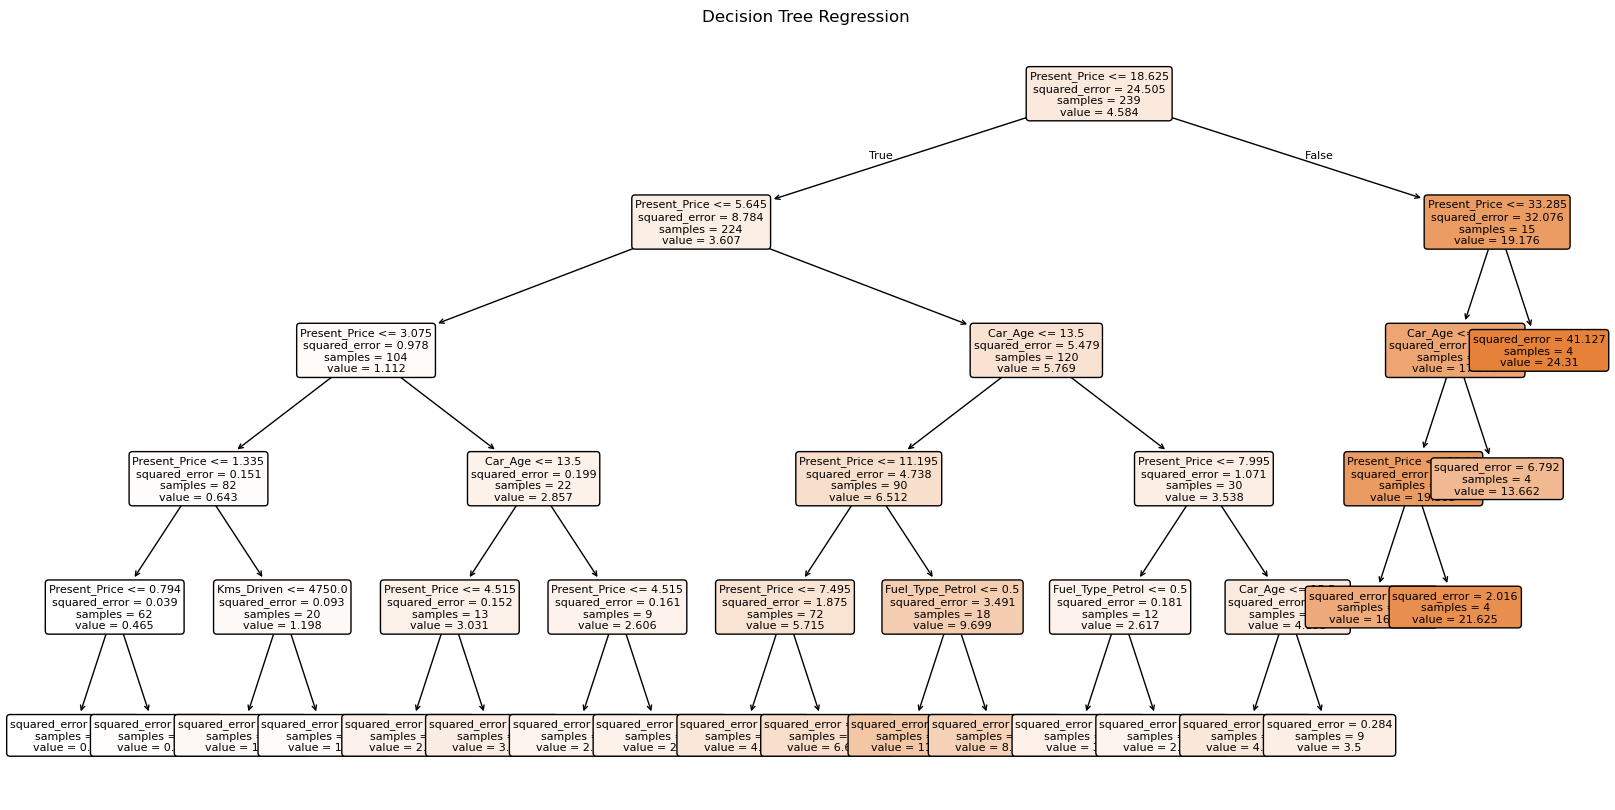

In [44]:
# ============================================================
# STEP 26: VISUALIZE DECISION TREE
# ============================================================

plt.figure(
    figsize=(20, 10)
)

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title(
    "Decision Tree Regression"
)

plt.show()

In [45]:
# ============================================================
# STEP 27: FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                  Feature  Importance
0           Present_Price    0.943587
3                 Car_Age    0.052653
5        Fuel_Type_Petrol    0.003584
1              Kms_Driven    0.000176
2                   Owner    0.000000
4        Fuel_Type_Diesel    0.000000
6  Seller_Type_Individual    0.000000
7     Transmission_Manual    0.000000


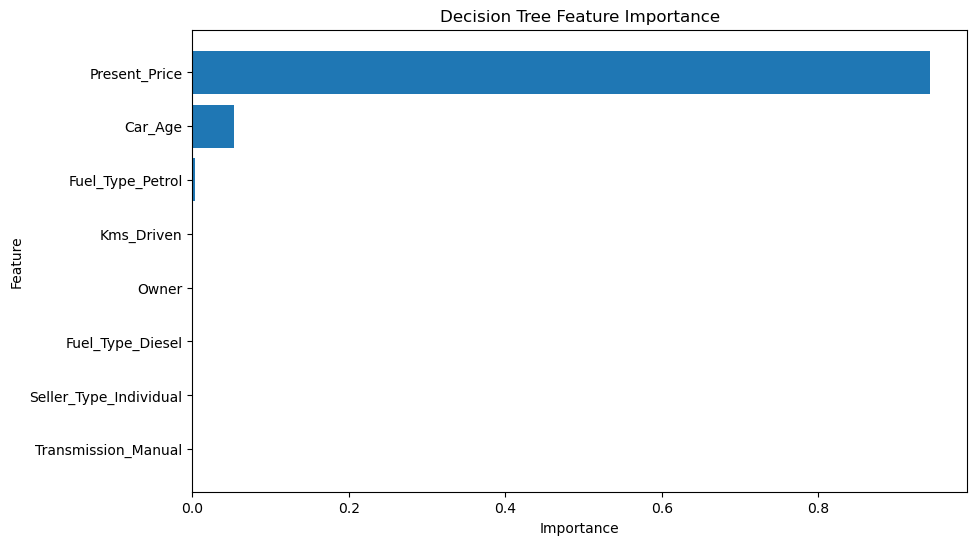

In [46]:
# ============================================================
# STEP 28: FEATURE IMPORTANCE GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Decision Tree Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

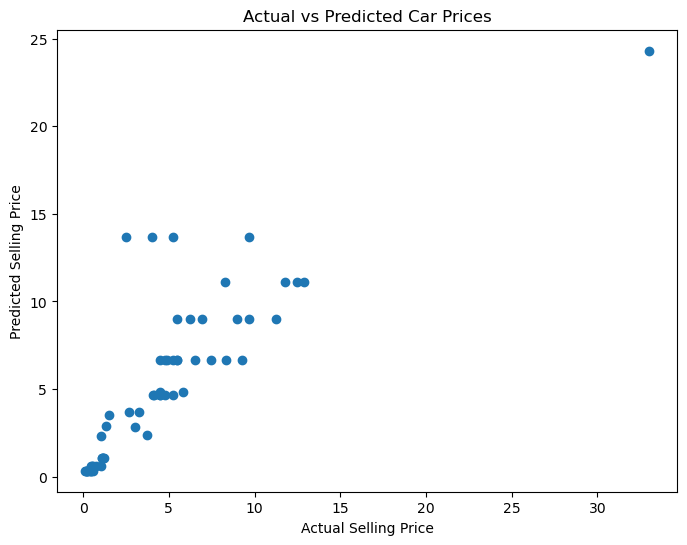

In [47]:
# ============================================================
# STEP 29: ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel(
    "Actual Selling Price"
)

plt.ylabel(
    "Predicted Selling Price"
)

plt.title(
    "Actual vs Predicted Car Prices"
)

plt.show()

In [48]:
# ============================================================
# STEP 30: CREATE NEW CAR DATA
# ============================================================

new_car = pd.DataFrame({
    "Year": [2018],
    "Present_Price": [8.5],
    "Kms_Driven": [25000],
    "Fuel_Type": ["Petrol"],
    "Seller_Type": ["Dealer"],
    "Transmission": ["Manual"],
    "Owner": [0]
})

print(new_car)

   Year  Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner
0  2018            8.5       25000    Petrol      Dealer       Manual      0


In [49]:
# ============================================================
# STEP 31: CREATE CAR AGE FOR NEW DATA
# ============================================================

new_car["Car_Age"] = (
    CURRENT_YEAR - new_car["Year"]
)

print(new_car)

   Year  Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner  \
0  2018            8.5       25000    Petrol      Dealer       Manual      0   

   Car_Age  
0        8  


In [50]:
# ============================================================
# STEP 32: DROP UNUSED COLUMNS
# ============================================================

new_car = new_car.drop(
    columns=["Year"]
)

In [51]:
# ============================================================
# STEP 33: ENCODE NEW DATA
# ============================================================

new_car = pd.get_dummies(
    new_car,
    columns=[
        "Fuel_Type",
        "Seller_Type",
        "Transmission"
    ],
    drop_first=True,
    dtype=int
)

In [52]:
# ============================================================
# STEP 34: ALIGN NEW DATA COLUMNS
# ============================================================

new_car = new_car.reindex(
    columns=X.columns,
    fill_value=0
)

print("\nFinal new car data:")
print(new_car)


Final new car data:
   Present_Price  Kms_Driven  Owner  Car_Age  Fuel_Type_Diesel  \
0            8.5       25000      0        8                 0   

   Fuel_Type_Petrol  Seller_Type_Individual  Transmission_Manual  
0                 0                       0                    0  


In [53]:
# ============================================================
# STEP 35: PREDICT NEW CAR PRICE
# ============================================================

new_prediction = model.predict(
    new_car
)

print(
    "\nPredicted Selling Price:",
    new_prediction[0]
)


Predicted Selling Price: 6.65421052631579


In [54]:
# ============================================================
# STEP 36: FINAL RESULT
# ============================================================

print("\n======================================")
print("NEW CAR PRICE PREDICTION")
print("======================================")

print(
    "Car Year: 2018"
)

print(
    "Present Price: ₹8.5 lakh"
)

print(
    "Kms Driven: 25,000"
)

print(
    "Fuel Type: Petrol"
)

print(
    "Seller Type: Dealer"
)

print(
    "Transmission: Manual"
)

print(
    "Owner: 0"
)

print(
    "Predicted Selling Price: ₹",
    round(new_prediction[0], 2),
    "lakh"
)


NEW CAR PRICE PREDICTION
Car Year: 2018
Present Price: ₹8.5 lakh
Kms Driven: 25,000
Fuel Type: Petrol
Seller Type: Dealer
Transmission: Manual
Owner: 0
Predicted Selling Price: ₹ 6.65 lakh
